# ADVANCED DEEP LEARNING Assignment 2 (Group 4)


| SL.NO | BITS ID     | NAME                   | CONTRIBUTION |
| ----- | ----------- | ---------------------- | ------------ |
| 1     | 2024AA05733 | Bollam Manindra        | 100%         |
| 2     | 2024AA05734 | S.Hari Chandana        | 100%         |
| 3     | 2024AA05732 | Ashvini Satish Boshale | 100%         |
| 4     | 2024AA05735 | Nikhil Yadav           | 100%         |
| 5     | 2024AA05946 | Deepthi Pullarkat      | 100%         |


# **Face Modification using VAE, β-VAE, VQ-VAE and GAN**


# Part A VAE


LOAD REQUIRED LIBRARIES


In [1]:
import os
import zipfile
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import torchvision.utils as vutils

Step 1: IMPORT DATASET - CELEB A Dataset


In [ ]:
# setting kaggle details from environment variables
os.environ['KAGGLE_USERNAME'] = os.getenv('KAGGLE_USERNAME', '')
os.environ['KAGGLE_KEY'] = os.getenv('KAGGLE_KEY', '')

# This creates the necessary config file automatically so the API works
!mkdir -p ~/.kaggle
!echo '{"username":"'$KAGGLE_USERNAME'","key":"'$KAGGLE_KEY'"}' > ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

print("Kaggle API successfully configured!")

Kaggle API successfully configured!


In [3]:
# 1. Download the zip file
!kaggle datasets download -d jessicali9530/celeba-dataset

# 2. Unzip file
with zipfile.ZipFile("celeba-dataset.zip", "r") as zip_ref:
    zip_ref.extractall("celeba_data")

print("Done")

Dataset URL: https://www.kaggle.com/datasets/jessicali9530/celeba-dataset
License(s): other
 97% 1.29G/1.33G [00:07<00:00, 38.7MB/s]
100% 1.33G/1.33G [00:07<00:00, 182MB/s] 
Done


STEP 2: PREPROCESSING


In [14]:
# Preprocessing
# resize to 64X64
# normalize to [0,1]
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(), # Automatically scales pixels to [0, 1.0]
])

# Load the dataset
full_dataset = datasets.ImageFolder(root='celeba_data/img_align_celeba', transform=transform)

batch_size = 128
dataloader = DataLoader(full_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dataset ready: Using {len(full_dataset)} images on {device}")

Dataset ready: Using 202599 images on cuda


## Define VAE Architecture


In [5]:
class Encoder(nn.Module):
    def __init__(self, latent_dim):
        super(Encoder, self).__init__()
        self.latent_dim = latent_dim

        # Convolutional layers for feature extraction
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=4, stride=2, padding=1), # 64x64 -> 32x32
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1), # 32x32 -> 16x16
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1), # 16x16 -> 8x8
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1), # 8x8 -> 4x4
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True)
        )

        # Fully connected layers for mean and log-variance
        # The output of conv_layers is 256 channels, 4x4 spatial dimensions
        self.fc_mu = nn.Linear(256 * 4 * 4, latent_dim)
        self.fc_log_var = nn.Linear(256 * 4 * 4, latent_dim)

    def forward(self, x):
        h = self.conv_layers(x)
        h = h.view(h.size(0), -1) # Flatten the tensor
        mu = self.fc_mu(h)
        log_var = self.fc_log_var(h)
        return mu, log_var

print("Encoder class defined.")

Encoder class defined.


In [6]:
class Decoder(nn.Module):
    def __init__(self, latent_dim):
        super(Decoder, self).__init__()
        self.latent_dim = latent_dim

        # First fully connected layer to project latent space to convolutional dimensions
        self.fc_decode = nn.Linear(latent_dim, 256 * 4 * 4)

        # Deconvolutional layers for image reconstruction
        self.deconv_layers = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1), # 4x4 -> 8x8
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1), # 8x8 -> 16x16
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),

            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1), # 16x16 -> 32x32
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2, inplace=True),

            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1), # 32x32 -> 64x64
            nn.Sigmoid() # Output pixels in [0, 1]
        )

    def forward(self, z):
        h = self.fc_decode(z)
        h = h.view(h.size(0), 256, 4, 4) # Reshape to 4x4 with 256 channels
        x_reconstructed = self.deconv_layers(h)
        return x_reconstructed

print("Decoder class defined.")

Decoder class defined.


In [7]:
class VAE(nn.Module):
    def __init__(self, latent_dim):
        super(VAE, self).__init__()
        self.encoder = Encoder(latent_dim)
        self.decoder = Decoder(latent_dim)

    def reparameterize(self, mu, log_var):
        std = torch.exp(0.5 * log_var)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        mu, log_var = self.encoder(x)
        z = self.reparameterize(mu, log_var)
        x_reconstructed = self.decoder(z)
        return x_reconstructed, mu, log_var

print("VAE class defined.")

VAE class defined.


## Define VAE Training Components


In [8]:
def vae_loss_function(recon_x, x, mu, log_var):
    # 1a. Reconstruction Loss: Binary Cross-Entropy
    # Flatten x and recon_x to apply BCELoss per pixel
    BCE = F.binary_cross_entropy(recon_x, x, reduction='sum')

    # 1b. KL Divergence Loss
    # KLD = -0.5 * sum(1 + log_var - mu^2 - exp(log_var))
    KLD = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp())

    # 1c. Total VAE Loss
    return BCE + KLD

print("VAE loss function defined.")

VAE loss function defined.


In [9]:
latent_dim = 128
vae_model = VAE(latent_dim).to(device)

learning_rate = 1e-3
optimizer = torch.optim.Adam(vae_model.parameters(), lr=learning_rate)

print(f"VAE model instantiated with latent_dim={latent_dim} and moved to {device}.")
print(f"Optimizer (Adam) initialized with learning_rate={learning_rate}.")

VAE model instantiated with latent_dim=128 and moved to cuda.
Optimizer (Adam) initialized with learning_rate=0.001.


## 1. Train the VAE


In [10]:
def train_vae(model, dataloader, optimizer, loss_function, device):
    model.train()  # Set the model to training mode
    running_loss = 0.0
    for i, (images, _) in enumerate(dataloader):
        images = images.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        recon_images, mu, log_var = model(images)

        # Calculate loss
        loss = loss_function(recon_images, images, mu, log_var)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    avg_loss = running_loss / len(dataloader.dataset)
    return avg_loss

print("Training function 'train_vae' defined.")

Training function 'train_vae' defined.


In [15]:
num_epochs = 5

print("Starting VAE training...")
for epoch in range(1, num_epochs + 1):
    epoch_loss = train_vae(vae_model, dataloader, optimizer, vae_loss_function, device)
    print(f"Epoch {epoch}/{num_epochs}, Loss: {epoch_loss:.4f}")

print("VAE training complete.")

Starting VAE training...
Epoch 1/5, Loss: 6241.9392
Epoch 2/5, Loss: 6240.5072
Epoch 3/5, Loss: 6239.4799
Epoch 4/5, Loss: 6238.6866
Epoch 5/5, Loss: 6237.8840
VAE training complete.


In [16]:
def show_images(image_tensor, title, nrow=8):
    # Ensure the image tensor is on CPU for visualization
    image_tensor = image_tensor.cpu()

    # Make a grid of images
    grid = vutils.make_grid(image_tensor, nrow=nrow, padding=2, normalize=True)

    # Convert to numpy array and transpose dimensions for matplotlib (C, H, W) -> (H, W, C)
    np_grid = grid.detach().numpy().transpose(1, 2, 0)

    plt.figure(figsize=(10, 10))
    plt.imshow(np_grid)
    plt.title(title)
    plt.axis('off')
    plt.show()

print("Visualization libraries imported and 'show_images' function defined.")

Visualization libraries imported and 'show_images' function defined.


## 2. Visualize Reconstructions


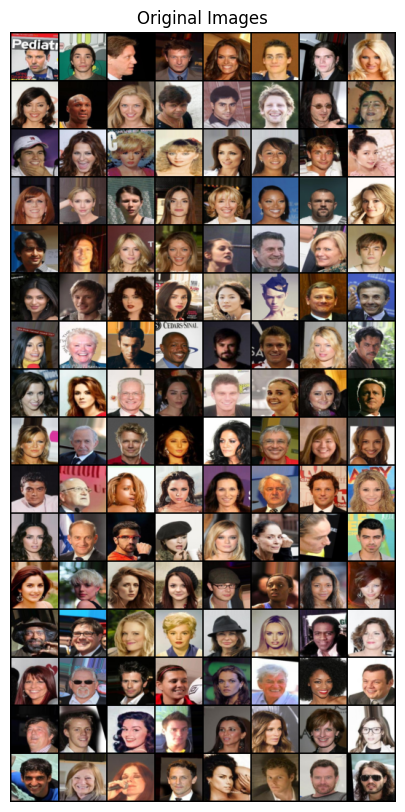

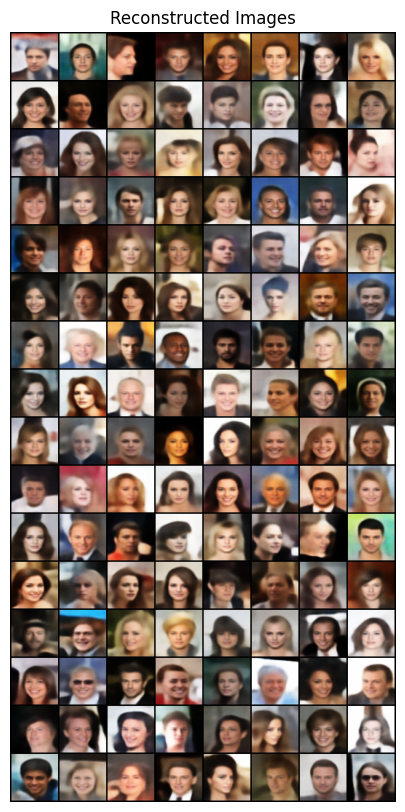

Original and reconstructed images displayed.


In [17]:
vae_model.eval() # Set the model to evaluation mode

# Get a batch of real images
dataiter = iter(dataloader)
images, _ = next(dataiter)
images = images.to(device)

# Pass images through VAE to get reconstructions
with torch.no_grad(): # Disable gradient calculation for inference
    recon_images, _, _ = vae_model(images)

# Display original images
show_images(images, 'Original Images')

# Display reconstructed images
show_images(recon_images, 'Reconstructed Images')

print("Original and reconstructed images displayed.")

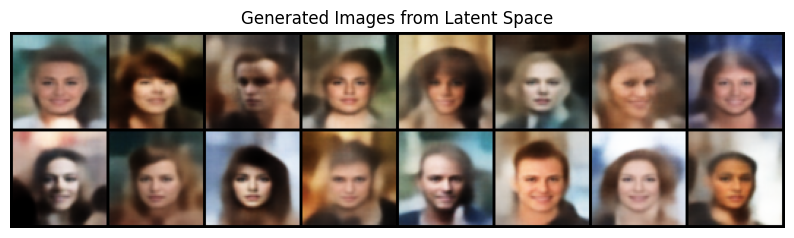

Successfully generated and displayed 16 new images.


In [18]:
vae_model.eval() # Ensure model is in evaluation mode

# Generate new images by sampling from the latent space
num_generated_images = 16 # Adjust as needed
sampled_latent_vectors = torch.randn(num_generated_images, latent_dim).to(device)

with torch.no_grad():
    generated_images = vae_model.decoder(sampled_latent_vectors)

# Display the newly generated images
show_images(generated_images, 'Generated Images from Latent Space')

print(f"Successfully generated and displayed {num_generated_images} new images.")

## Summary:

- **Reconstruction and generation results**
  The model successfully reconstructed input images, demonstrating its ability to learn and reproduce visual features.
  It demonstrated generative capabilities by producing novel images when sampling from its latent space.
- **How was the model's performance discussed, and what are potential next steps?**
  The model showed good initial performance by successfully learning to reconstruct images and generate new ones, as evidenced by decreasing training loss and visual inspection of outputs.


## 3. Perform latent interpolation between two faces


In [19]:
vae_model.eval()

#Obtain a batch of images from the dataloader
try:
    sample_images, _ = next(iter(dataloader))
except StopIteration:
    dataloader_iterator = iter(dataloader)
    sample_images, _ = next(dataloader_iterator)

# Select two distinct images from this batch and move them to the device
image1 = sample_images[0].unsqueeze(0).to(device) # unsqueeze to add batch dimension
image2 = sample_images[1].unsqueeze(0).to(device) # unsqueeze to add batch dimension

# Pass each selected image through the vae_model.encoder to obtain their latent mean vectors (mu)
with torch.no_grad():
    mu1, _ = vae_model.encoder(image1)
    mu2, _ = vae_model.encoder(image2)

# Store these two mean vectors
start_latent = mu1
end_latent = mu2

print("Two distinct images selected and their latent mean vectors ('start_latent' and 'end_latent') obtained.")
print(f"Shape of start_latent: {start_latent.shape}")
print(f"Shape of end_latent: {end_latent.shape}")

# store the original images for later visualization
selected_original_images = torch.cat((image1, image2), dim=0)


Two distinct images selected and their latent mean vectors ('start_latent' and 'end_latent') obtained.
Shape of start_latent: torch.Size([1, 128])
Shape of end_latent: torch.Size([1, 128])


In [20]:
selected_original_images

tensor([[[[0.5176, 0.5020, 0.4275,  ..., 0.4471, 0.4196, 0.3490],
          [0.5176, 0.5020, 0.4275,  ..., 0.4471, 0.4196, 0.3490],
          [0.5176, 0.5020, 0.4275,  ..., 0.4510, 0.4157, 0.3451],
          ...,
          [0.3647, 0.3882, 0.3922,  ..., 0.3294, 0.3412, 0.3569],
          [0.3843, 0.3882, 0.4039,  ..., 0.3333, 0.3412, 0.3490],
          [0.3922, 0.3922, 0.3922,  ..., 0.3451, 0.3569, 0.3686]],

         [[0.4902, 0.4667, 0.3804,  ..., 0.4392, 0.4039, 0.3216],
          [0.4902, 0.4667, 0.3804,  ..., 0.4392, 0.4039, 0.3216],
          [0.4902, 0.4667, 0.3804,  ..., 0.4392, 0.4000, 0.3216],
          ...,
          [0.3373, 0.3569, 0.3569,  ..., 0.2941, 0.3059, 0.3216],
          [0.3529, 0.3569, 0.3686,  ..., 0.2980, 0.3059, 0.3137],
          [0.3608, 0.3608, 0.3608,  ..., 0.3098, 0.3216, 0.3333]],

         [[0.2157, 0.2431, 0.2157,  ..., 0.2941, 0.2549, 0.1765],
          [0.2157, 0.2431, 0.2157,  ..., 0.2941, 0.2549, 0.1765],
          [0.2157, 0.2431, 0.2196,  ..., 0

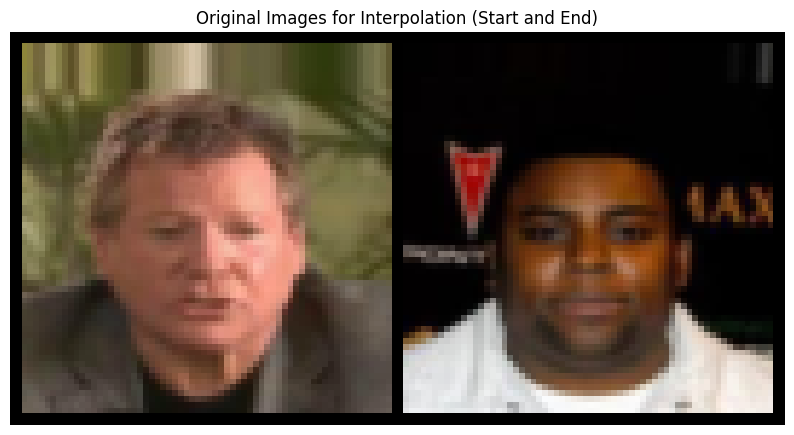

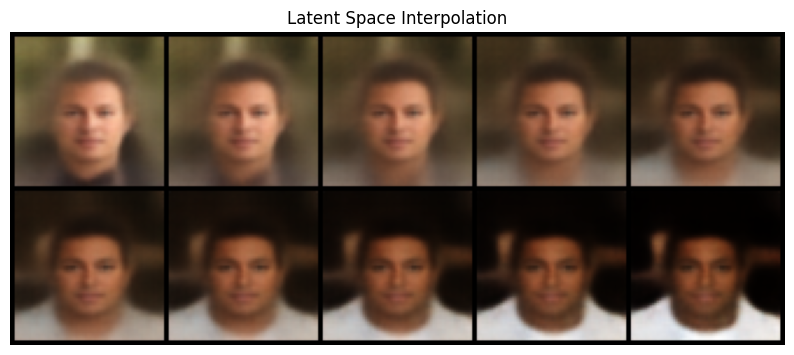

Generated and displayed 10 interpolated images.


In [21]:
num_interpolation_steps = 10 # Define the number of steps for interpolation

# Create interpolation weights from 0 to 1
interpolation_weights = torch.linspace(0, 1, num_interpolation_steps).to(device)

interpolated_images = []
vae_model.eval() # Ensure model is in evaluation mode

with torch.no_grad():
    for alpha in interpolation_weights:
        # Linear interpolation in latent space
        interpolated_latent_vector = (1 - alpha) * start_latent + alpha * end_latent

        # Decode the interpolated latent vector to generate an image
        generated_image = vae_model.decoder(interpolated_latent_vector)
        interpolated_images.append(generated_image)

# Concatenate all generated images and display them
# The interpolated_images list contains tensors of shape (1, C, H, W)
interpolated_images_tensor = torch.cat(interpolated_images, dim=0)

# Display the selected original images alongside the interpolation for context
show_images(selected_original_images, 'Original Images for Interpolation (Start and End)', nrow=2)
show_images(interpolated_images_tensor, 'Latent Space Interpolation', nrow=num_interpolation_steps // 2)

print(f"Generated and displayed {num_interpolation_steps} interpolated images.")

## Summary:

The latent interpolation process involved selecting two distinct images, encoding them using the VAE's encoder to obtain their 128-dimensional latent mean vectors (`start_latent` and `end_latent`), and then linearly interpolating between these two vectors in 10 steps. Each intermediate latent vector was subsequently decoded by the VAE's decoder to generate a new image. The successful display of the images implies a visual demonstration of a smooth transition or morphing between the two initial faces, indicating that the VAE's latent space effectively captures meaningful variations.


# 4. Perform attribute modification by vector arithmetic


## Identify Attribute and Collect Samples


In [22]:
import os
import pandas as pd

attr_file_path = os.path.join('celeba_data', 'list_attr_celeba.csv')

# Define the correct 40 attribute names for CelebA dataset
celeba_attribute_names = [
    '5_o_Clock_Shadow', 'Arched_Eyebrows', 'Attractive', 'Bags_Under_Eyes', 'Bald',
    'Bangs', 'Big_Lips', 'Big_Nose', 'Black_Hair', 'Blond_Hair', 'Blurry',
    'Brown_Hair', 'Bushy_Eyebrows', 'Chubby', 'Double_Chin', 'Edgy_Hair',
    'Eyeglasses', 'Goatee', 'Gray_Hair', 'Heavy_Makeup', 'High_Cheekbones',
    'Male', 'Mouth_Slightly_Open', 'Mustache', 'Narrow_Eyes', 'No_Beard',
    'Oval_Face', 'Pale_Skin', 'Pointy_Nose', 'Receding_Hairline', 'Rosy_Cheeks',
    'Sideburns', 'Smiling', 'Straight_Hair', 'Wavy_Hair', 'Wearing_Earrings',
    'Wearing_Hat', 'Wearing_Lipstick', 'Wearing_Necklace', 'Wearing_Necktie'
]

# Load the attribute annotation file into a pandas DataFrame
attributes_df = pd.read_csv(
    attr_file_path,
    sep=',',
    skiprows=1,
    header=None,
    names=['image_id'] + celeba_attribute_names,
    index_col=0
)

# Preprocess the DataFrame: Convert attribute values from '-1' to '0'
attributes_df = attributes_df.replace({-1: 0})

# Print confirmation, shape, and first 5 rows
print("Attribute annotations loaded and preprocessed with correct attribute names.")
print(f"DataFrame shape: {attributes_df.shape}")
print("First 5 rows of the preprocessed DataFrame:")
print(attributes_df.head())
print("\nColumn names:")
print(attributes_df.columns.tolist())

Attribute annotations loaded and preprocessed with correct attribute names.
DataFrame shape: (202599, 40)
First 5 rows of the preprocessed DataFrame:
            5_o_Clock_Shadow  Arched_Eyebrows  Attractive  Bags_Under_Eyes  \
image_id                                                                     
000001.jpg                 0                1           1                0   
000002.jpg                 0                0           0                1   
000003.jpg                 0                0           0                0   
000004.jpg                 0                0           1                0   
000005.jpg                 0                1           1                0   

            Bald  Bangs  Big_Lips  Big_Nose  Black_Hair  Blond_Hair  ...  \
image_id                                                             ...   
000001.jpg     0      0         0         0           0           0  ...   
000002.jpg     0      0         0         1           0           0  ...   

Attribute: Smiling


In [23]:
vae_model.eval() # Set the VAE model to evaluation mode

selected_attribute = 'Smiling'
num_samples_per_category = 1000 # Limit the number of samples to collect for each category

latent_vectors_attr_present = []
latent_vectors_attr_absent = []

count_present = 0
count_absent = 0

print(f"Collecting latent vectors for images with and without '{selected_attribute}'...")

# Iterate through the subset dataset (fast_dataset)
for i in range(len(fast_dataset)):
    if count_present >= num_samples_per_category and count_absent >= num_samples_per_category:
        break

    original_idx = fast_dataset.indices[i]
    image_path, _ = full_dataset.samples[original_idx]
    image_filename = os.path.basename(image_path)

    if image_filename not in attributes_df.index:
        continue

    attribute_value = attributes_df.loc[image_filename, selected_attribute]

    image_tensor, _ = fast_dataset[i]
    image_tensor = image_tensor.unsqueeze(0).to(device) # Add batch dimension and move to device

    with torch.no_grad():
        mu, _ = vae_model.encoder(image_tensor)

    if attribute_value == 1 and count_present < num_samples_per_category:
        latent_vectors_attr_present.append(mu.cpu())
        count_present += 1
    elif attribute_value == 0 and count_absent < num_samples_per_category:
        latent_vectors_attr_absent.append(mu.cpu())
        count_absent += 1

# Concatenate collected latent vectors into single tensors
latent_vectors_attr_present = torch.cat(latent_vectors_attr_present, dim=0) if latent_vectors_attr_present else torch.empty(0, latent_dim)
latent_vectors_attr_absent = torch.cat(latent_vectors_attr_absent, dim=0) if latent_vectors_attr_absent else torch.empty(0, latent_dim)

print(f"Collected {len(latent_vectors_attr_present)} latent vectors for '{selected_attribute}' present.")
print(f"Collected {len(latent_vectors_attr_absent)} latent vectors for '{selected_attribute}' absent.")


Collected 1000 latent vectors for 'Smiling' present.
Collected 1000 latent vectors for 'Smiling' absent.


In [24]:
#calculate attribute vector
# Calculate the mean of the collected latent_vectors_attr_present
mean_attr_present = torch.mean(latent_vectors_attr_present, dim=0)

# Calculate the mean of the collected latent_vectors_attr_absent
mean_attr_absent = torch.mean(latent_vectors_attr_absent, dim=0)

# Compute the attribute_vector by subtracting mean_attr_absent from mean_attr_present
attribute_vector = mean_attr_present - mean_attr_absent

print(f"Attribute vector for '{selected_attribute}' calculated.")
print(f"Shape of attribute_vector: {attribute_vector.shape}")

Attribute vector for 'Smiling' calculated.
Shape of attribute_vector: torch.Size([128])


## Apply Attribute Vector to Modify Faces


In [25]:
vae_model.eval() # Ensure model is in evaluation mode

num_images_to_modify = 5
selected_images_for_modification = []
selected_latent_mus = []

# pick new image
dataiter_modify = iter(dataloader)

for _ in range(num_images_to_modify):
    try:
        images, _ = next(dataiter_modify)
    except StopIteration:
        dataloader_modify = iter(dataloader)
        images, _ = next(dataloader_modify)


    img = images[0].unsqueeze(0).to(device)
    selected_images_for_modification.append(img.cpu())

    with torch.no_grad():
        mu, _ = vae_model.encoder(img)
        selected_latent_mus.append(mu.cpu())

print(f"Selected {num_images_to_modify} original images and encoded them to obtain their latent means.")
print(f"Number of latent vectors collected: {len(selected_latent_mus)}")
print(f"Shape of first latent vector: {selected_latent_mus[0].shape}")


Selected 5 original images and encoded them to obtain their latent means.
Number of latent vectors collected: 5
Shape of first latent vector: torch.Size([1, 128])


In [26]:
modification_strengths = torch.linspace(-3.0, 3.0, steps=7).to(device) # Define a range of alpha values, e.g., from -3 to +3

modified_latent_vectors_per_image = []

attribute_vector = attribute_vector.to(device)

for original_latent_mu in selected_latent_mus:
    original_latent_mu = original_latent_mu.to(device)
    modified_latents_for_one_image = []
    for alpha in modification_strengths:
        modified_latent = original_latent_mu + alpha * attribute_vector
        modified_latents_for_one_image.append(modified_latent)
    modified_latent_vectors_per_image.append(torch.cat(modified_latents_for_one_image, dim=0))

print(f"Defined {len(modification_strengths)} modification strengths.")
print(f"Created modified latent vectors for {len(selected_latent_mus)} images.")
print(f"Shape of modified latent vectors for one image: {modified_latent_vectors_per_image[0].shape}")

Defined 7 modification strengths.
Created modified latent vectors for 5 images.
Shape of modified latent vectors for one image: torch.Size([7, 128])


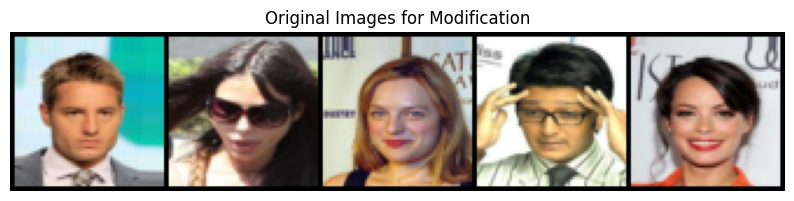

Displaying 5 original images and their 7 modified versions for 'Smiling'.


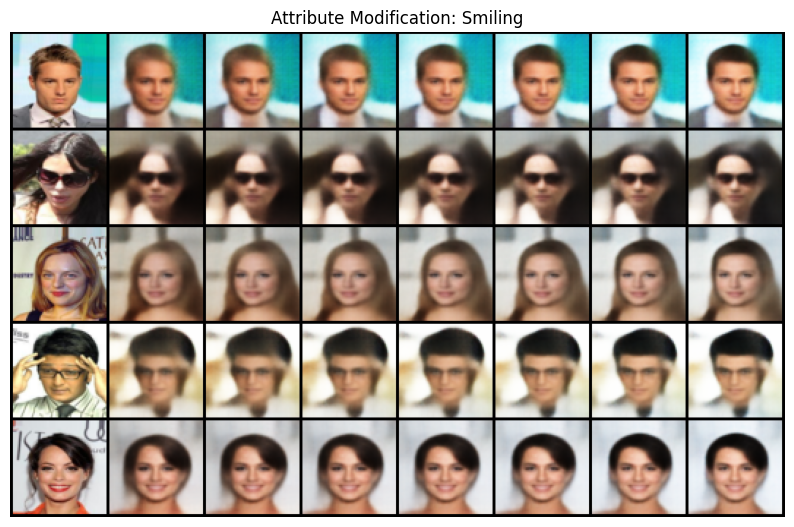

In [27]:
vae_model.eval()
all_generated_images = []

with torch.no_grad():

    for original_img_tensor in selected_images_for_modification:
        all_generated_images.append(original_img_tensor)

    # Decode the modified latent vectors for each original image
    for i, modified_latents_for_one_image in enumerate(modified_latent_vectors_per_image):

        generated_images_for_one_row = vae_model.decoder(modified_latents_for_one_image)

        row_to_display = torch.cat([
            selected_images_for_modification[i].to(device),
            generated_images_for_one_row
        ], dim=0)
        all_generated_images.append(row_to_display.cpu())

# Create a single tensor from all images to display
final_display_tensor = torch.cat([img for img_group in all_generated_images for img in img_group], dim=0)

num_cols = 1 + len(modification_strengths)
show_images(
    torch.cat(selected_images_for_modification, dim=0),
    'Original Images for Modification',
    nrow=num_images_to_modify
)

images_for_grid_display = []
for i, original_img in enumerate(selected_images_for_modification):
    images_for_grid_display.append(original_img)
    with torch.no_grad():
        decoded_modified_images = vae_model.decoder(modified_latent_vectors_per_image[i].to(device))
    images_for_grid_display.append(decoded_modified_images.cpu())

rows_to_display = []
for i in range(num_images_to_modify):
    original_img = selected_images_for_modification[i]
    with torch.no_grad():
        modified_imgs = vae_model.decoder(modified_latent_vectors_per_image[i].to(device)).cpu()
    rows_to_display.append(torch.cat([original_img, modified_imgs], dim=0))

# Stack all rows vertically for final display
final_display_grid = torch.cat(rows_to_display, dim=0)

print(f"Displaying {num_images_to_modify} original images and their {len(modification_strengths)} modified versions for '{selected_attribute}'.")
show_images(final_display_grid, f'Attribute Modification: {selected_attribute}', nrow=num_cols)


Apply Attribute 'Bald'


In [28]:
vae_model.eval()

selected_attribute = 'Bald'
num_samples_per_category = 5000

latent_vectors_attr_present = []
latent_vectors_attr_absent = []

count_present = 0
count_absent = 0

print(f"Collecting latent vectors for images with and without '{selected_attribute}'...")

for i in range(len(fast_dataset)):
    if count_present >= num_samples_per_category and count_absent >= num_samples_per_category:
        break

    original_idx = fast_dataset.indices[i]

    image_path, _ = full_dataset.samples[original_idx]
    image_filename = os.path.basename(image_path)

    if image_filename not in attributes_df.index:
        continue

    attribute_value = attributes_df.loc[image_filename, selected_attribute]

    image_tensor, _ = fast_dataset[i]
    image_tensor = image_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        mu, _ = vae_model.encoder(image_tensor)

    if attribute_value == 1 and count_present < num_samples_per_category:
        latent_vectors_attr_present.append(mu.cpu())
        count_present += 1
    elif attribute_value == 0 and count_absent < num_samples_per_category:
        latent_vectors_attr_absent.append(mu.cpu())
        count_absent += 1

latent_vectors_attr_present = torch.cat(latent_vectors_attr_present, dim=0) if latent_vectors_attr_present else torch.empty(0, latent_dim)
latent_vectors_attr_absent = torch.cat(latent_vectors_attr_absent, dim=0) if latent_vectors_attr_absent else torch.empty(0, latent_dim)

print(f"Collected {len(latent_vectors_attr_present)} latent vectors for '{selected_attribute}' present.")
print(f"Collected {len(latent_vectors_attr_absent)} latent vectors for '{selected_attribute}' absent.")

Collected 2238 latent vectors for 'Bald' present.
Collected 5000 latent vectors for 'Bald' absent.


In [29]:
mean_attr_present = torch.mean(latent_vectors_attr_present, dim=0)
mean_attr_absent = torch.mean(latent_vectors_attr_absent, dim=0)
attribute_vector = mean_attr_present - mean_attr_absent

print(f"Attribute vector for '{selected_attribute}' calculated.")
print(f"Shape of attribute_vector: {attribute_vector.shape}")

Attribute vector for 'Bald' calculated.
Shape of attribute_vector: torch.Size([128])


In [30]:
vae_model.eval()

num_images_to_modify = 5
selected_images_for_modification = []
selected_latent_mus = []

dataiter_modify = iter(dataloader)

for _ in range(num_images_to_modify):
    try:
        images, _ = next(dataiter_modify)
    except StopIteration:
        dataloader_modify = iter(dataloader)
        images, _ = next(dataloader_modify)


    img = images[0].unsqueeze(0).to(device)
    selected_images_for_modification.append(img.cpu())

    with torch.no_grad():
        mu, _ = vae_model.encoder(img)
        selected_latent_mus.append(mu.cpu())

print(f"Selected {num_images_to_modify} original images and encoded them to obtain their latent means.")
print(f"Number of latent vectors collected: {len(selected_latent_mus)}")
print(f"Shape of first latent vector: {selected_latent_mus[0].shape}")

Selected 5 original images and encoded them to obtain their latent means.
Number of latent vectors collected: 5
Shape of first latent vector: torch.Size([1, 128])


In [31]:
modification_strengths = torch.linspace(-3.0, 3.0, steps=7).to(device)

modified_latent_vectors_per_image = []


attribute_vector = attribute_vector.to(device)

for original_latent_mu in selected_latent_mus:
    original_latent_mu = original_latent_mu.to(device)
    modified_latents_for_one_image = []
    for alpha in modification_strengths:
        modified_latent = original_latent_mu + alpha * attribute_vector
        modified_latents_for_one_image.append(modified_latent)
    modified_latent_vectors_per_image.append(torch.cat(modified_latents_for_one_image, dim=0))

print(f"Defined {len(modification_strengths)} modification strengths.")
print(f"Created modified latent vectors for {len(selected_latent_mus)} images.")
print(f"Shape of modified latent vectors for one image: {modified_latent_vectors_per_image[0].shape}")

Defined 7 modification strengths.
Created modified latent vectors for 5 images.
Shape of modified latent vectors for one image: torch.Size([7, 128])


Displaying 5 original images and their 7 modified versions for 'Bald'.


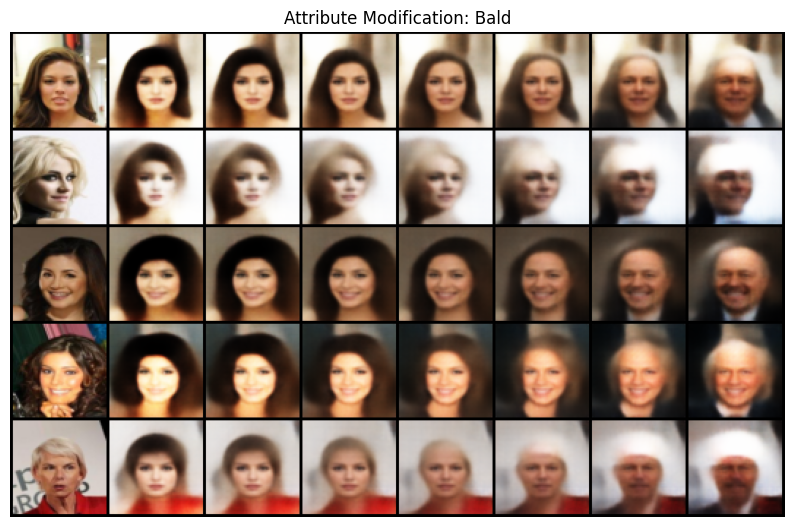

In [32]:
vae_model.eval()

rows_to_display = []

for i in range(num_images_to_modify):
    original_img = selected_images_for_modification[i]
    with torch.no_grad():
        modified_imgs = vae_model.decoder(modified_latent_vectors_per_image[i].to(device)).cpu()
    rows_to_display.append(torch.cat([original_img, modified_imgs], dim=0))

final_display_grid = torch.cat(rows_to_display, dim=0)

num_cols = 1 + len(modification_strengths)

print(f"Displaying {num_images_to_modify} original images and their {len(modification_strengths)} modified versions for '{selected_attribute}'.")
show_images(final_display_grid, f'Attribute Modification: {selected_attribute}', nrow=num_cols)

## Summary:

- After loading the attributes file, attribute values were converted from -1 to 0 for consistency, representing the absence of an attribute.
- For the selected attributes (smiling and bald, the selected images from converted from original to those attributes).
- However, we also see that other attributes that are highly correlated with these attributes were also added in some cases (e.g. bald+moustache)


# Part B: β-VAE


## 1. Setup and Imports


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import torchvision
from torchvision import transforms
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import os
import random
from PIL import Image

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

Using device: cuda


## 2. Data Loading


In [ ]:
# Configuration
IMG_SIZE = 64  # Can use 128 for higher quality
BATCH_SIZE = 64
NUM_WORKERS = 4

# Data transforms
transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    # Normalize to [0, 1] is already done by ToTensor()
])

### Option 1: Load CelebA from Kaggle (Recommended)

```bash
# Install Kaggle API
pip install kaggle

# Download CelebA from Kaggle
kaggle datasets download -d jessicali9530/celeba-dataset
unzip celeba-dataset.zip -d ./data/celeba
```


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

### Option 2: Manual Download

Download from: https://www.kaggle.com/datasets/jessicali9530/celeba-dataset
Or from: https://mmlab.ie.cuhk.edu.hk/projects/CelebA.html


In [ ]:
# Custom Dataset class for manually downloaded CelebA
class CelebADataset(Dataset):
    def __init__(self, root_dir, transform=None, split='train', max_samples=None):
        """
        Args:
            root_dir: Path to img_align_celeba folder
            transform: Transformations to apply
            split: 'train', 'val', or 'test'
            max_samples: Limit number of samples (useful for testing)
        """
        self.root_dir = root_dir
        self.transform = transform

        # Get all image files
        all_files = sorted([f for f in os.listdir(root_dir) if f.endswith('.jpg')])

        # Split dataset (CelebA has 202,599 images)
        # Train: 162,770 | Val: 19,867 | Test: 19,962
        if split == 'train':
            self.image_files = all_files[:162770]
        elif split == 'val':
            self.image_files = all_files[162770:182637]
        else:  # test
            self.image_files = all_files[182637:]

        if max_samples:
            self.image_files = self.image_files[:max_samples]

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, self.image_files[idx])
        image = Image.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        return image, 0  # Return 0 as dummy label for compatibility

In [ ]:
# Load CelebA dataset (real data from Kaggle)
CELEBA_PATH = './data/celeba/img_align_celeba/img_align_celeba'

print(f"Loading CelebA data from: {CELEBA_PATH}")
# Ensure the directory exists and contains images before proceeding
if not os.path.exists(CELEBA_PATH):
    print(f"Error: Directory not found: {CELEBA_PATH}. Please ensure the dataset was downloaded and unzipped correctly.")
    num_images = 0 # Prevent error if directory doesn't exist yet
else:
    num_images = len([f for f in os.listdir(CELEBA_PATH) if f.endswith('.jpg')])

print(f"Available images: {num_images}")

if num_images > 0:
    # Create datasets
    train_dataset = CelebADataset(
        root_dir=CELEBA_PATH,
        transform=transform,
        split='train',
        max_samples=None  # Use all data (set to e.g., 10000 for quick testing)
    )

    test_dataset = CelebADataset(
        root_dir=CELEBA_PATH,
        transform=transform,
        split='test',
        max_samples=None
    )

    # Create dataloaders
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )

    print(f"\nTrain dataset size: {len(train_dataset)}")
    print(f"Test dataset size: {len(test_dataset)}")
    print(f"Total CelebA images available: {len(train_dataset) + len(test_dataset)}")
else:
    print("No images found. Data loading will be skipped.")
    train_loader = None
    test_loader = None

Loading CelebA data from: ./data/celeba/img_align_celeba/img_align_celeba
Error: Directory not found: ./data/celeba/img_align_celeba/img_align_celeba. Please ensure the dataset was downloaded and unzipped correctly.
Available images: 0
No images found. Data loading will be skipped.


In [ ]:
print('Checking directory and file permissions:')
!ls -la ~/.kaggle

Checking directory and file permissions:
total 16
drwxr-xr-x 2 root root 4096 Feb  8 06:16 .
drwx------ 1 root root 4096 Feb  8 06:15 ..
-rw------- 1 root root   71 Feb  8 06:16 kaggle.json


In [ ]:
print('\nChecking kaggle.json content:')
!cat ~/.kaggle/kaggle.json


Checking kaggle.json content:
{"username":"Chandana4h","key":"KGAT_1e855a309827d44fc270464af286ae5c"}

In [ ]:
print('Checking directory and file permissions:')
!ls -la ~/.kaggle

Checking directory and file permissions:
total 16
drwxr-xr-x 2 root root 4096 Feb  8 06:16 .
drwx------ 1 root root 4096 Feb  8 06:15 ..
-rw------- 1 root root   71 Feb  8 06:16 kaggle.json


In [ ]:
print('\nChecking kaggle.json content:')
!cat ~/.kaggle/kaggle.json


Checking kaggle.json content:
{"username":"Chandana4h","key":"KGAT_1e855a309827d44fc270464af286ae5c"}

In [ ]:
!mkdir -p ~/.kaggle

In [ ]:
import json

# Using 'colab_user' as a placeholder username, as the token is the primary credential.

kaggle_credentials = {"username":"colab_user","key":"KGAT_390dbc0f7ce08e93b965e815a7a7624e"}
with open('/root/.kaggle/kaggle.json', 'w') as file:
    json.dump(kaggle_credentials, file)
!chmod 600 /root/.kaggle/kaggle.json
print('kaggle.json created and permissions set.')

kaggle.json created and permissions set.


In [ ]:
import os

# Set the KAGGLE_API_TOKEN environment variable
os.environ['KAGGLE_API_TOKEN'] = 'KGAT_390dbc0f7ce08e93b965e815a7a7624e'
print('KAGGLE_API_TOKEN environment variable set.')

KAGGLE_API_TOKEN environment variable set.


In [ ]:
# Download CelebA from Kaggle
# This command will now succeed if kaggle.json is properly configured.
!kaggle datasets download -d jessicali9530/celeba-dataset -p ./data/celeba

Dataset URL: https://www.kaggle.com/datasets/jessicali9530/celeba-dataset
License(s): other
celeba-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


In [51]:
# Unzip celeba-dataset.zip into the target directory
# This command will now succeed if the dataset was downloaded.
!unzip -q ./data/celeba/celeba-dataset.zip -d ./data/celeba

replace ./data/celeba/list_attr_celeba.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace ./data/celeba/list_bbox_celeba.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace ./data/celeba/list_eval_partition.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace ./data/celeba/list_landmarks_align_celeba.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y


In [53]:
# Load CelebA dataset (real data from Kaggle)
CELEBA_PATH = './data/celeba/img_align_celeba/img_align_celeba'

print(f"Loading CelebA data from: {CELEBA_PATH}")
# Ensure the directory exists and contains images before proceeding
if not os.path.exists(CELEBA_PATH):
    print(f"Error: Directory not found: {CELEBA_PATH}. Please ensure the dataset was downloaded and unzipped correctly.")
    num_images = 0 # Prevent error if directory doesn't exist yet
else:
    num_images = len([f for f in os.listdir(CELEBA_PATH) if f.endswith('.jpg')])

print(f"Available images: {num_images}")

if num_images > 0:
    # Create datasets
    train_dataset = CelebADataset(
        root_dir=CELEBA_PATH,
        transform=transform,
        split='train',
        max_samples=None  # Use all data (set to e.g., 10000 for quick testing)
    )

    test_dataset = CelebADataset(
        root_dir=CELEBA_PATH,
        transform=transform,
        split='test',
        max_samples=None
    )

    # Create dataloaders
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )

    print(f"\nTrain dataset size: {len(train_dataset)}")
    print(f"Test dataset size: {len(test_dataset)}")
    print(f"Total CelebA images available: {len(train_dataset) + len(test_dataset)}")
else:
    print("No images found. Data loading will be skipped.")
    train_loader = None
    test_loader = None

Loading CelebA data from: ./data/celeba/img_align_celeba/img_align_celeba
Available images: 202599

Train dataset size: 162770
Test dataset size: 19962
Total CelebA images available: 182732


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


In [54]:
pip install kaggle

In [55]:
import os
# Create the directory structure where the dataset will be unzipped
os.makedirs('./data/celeba/img_align_celeba', exist_ok=True)
print("Directory './data/celeba/img_align_celeba' ensured.")

Directory './data/celeba/img_align_celeba' ensured.


## 3. β-VAE Model


In [56]:
import torch
import torch.nn as nn
import torch.nn.functional as F

LATENT_DIM = 32

class BetaVAE(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1),
            nn.ReLU(),
            nn.Conv2d(32, 64, 4, 2, 1),
            nn.ReLU(),
            nn.Conv2d(64, 128, 4, 2, 1),
            nn.ReLU(),
            nn.Flatten()
        )

        self.fc_mu = nn.Linear(128 * 8 * 8, LATENT_DIM)
        self.fc_logvar = nn.Linear(128 * 8 * 8, LATENT_DIM)

        self.fc_dec = nn.Linear(LATENT_DIM, 128 * 8 * 8)

        self.decoder = nn.Sequential(
            nn.Unflatten(1, (128, 8, 8)),
            nn.ConvTranspose2d(128, 64, 4, 2, 1),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, 2, 1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 3, 4, 2, 1),
            nn.Sigmoid()
        )

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decoder(self.fc_dec(z))
        return x_hat, mu, logvar, z


## 4. β-VAE Loss


In [57]:
def beta_vae_loss(x, x_hat, mu, logvar, beta):
    recon = F.mse_loss(x_hat, x, reduction='sum')
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon + beta * kl

## 5. Training Loop (β = 2, 4, 10)


In [60]:
def train_beta_vae(beta, train_loader, epochs=10):
    model = BetaVAE().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    model.train()
    for epoch in range(epochs):
        total_loss = 0

        for batch in train_loader:
            x = batch[0].to(device)   # <-- FIX HERE

            x_hat, mu, logvar, _ = model(x)
            loss = beta_vae_loss(x, x_hat, mu, logvar, beta)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader.dataset)
        print(f"β={beta} | Epoch {epoch+1}/{epochs} | Loss: {avg_loss:.4f}")

    return model


## 6. Train with different beta values


In [61]:
vae_beta2  = train_beta_vae(beta=2,  train_loader=train_loader)
vae_beta4  = train_beta_vae(beta=4,  train_loader=train_loader)
vae_beta10 = train_beta_vae(beta=10, train_loader=train_loader)


β=2 | Epoch 1/10 | Loss: 279.9438
β=2 | Epoch 2/10 | Loss: 242.9114
β=2 | Epoch 3/10 | Loss: 238.8357
β=2 | Epoch 4/10 | Loss: 236.7347
β=2 | Epoch 5/10 | Loss: 235.3482
β=2 | Epoch 6/10 | Loss: 234.1939
β=2 | Epoch 7/10 | Loss: 233.4300
β=2 | Epoch 8/10 | Loss: 232.8276
β=2 | Epoch 9/10 | Loss: 232.2206
β=2 | Epoch 10/10 | Loss: 231.8032
β=4 | Epoch 1/10 | Loss: 341.5549
β=4 | Epoch 2/10 | Loss: 302.9958
β=4 | Epoch 3/10 | Loss: 298.5037
β=4 | Epoch 4/10 | Loss: 296.2267
β=4 | Epoch 5/10 | Loss: 294.7969
β=4 | Epoch 6/10 | Loss: 293.8072
β=4 | Epoch 7/10 | Loss: 292.8899
β=4 | Epoch 8/10 | Loss: 292.3395
β=4 | Epoch 9/10 | Loss: 291.8593
β=4 | Epoch 10/10 | Loss: 291.4025
β=10 | Epoch 1/10 | Loss: 439.0039
β=10 | Epoch 2/10 | Loss: 402.7813
β=10 | Epoch 3/10 | Loss: 399.3531
β=10 | Epoch 4/10 | Loss: 397.5591
β=10 | Epoch 5/10 | Loss: 396.0741
β=10 | Epoch 6/10 | Loss: 395.4297
β=10 | Epoch 7/10 | Loss: 394.6290
β=10 | Epoch 8/10 | Loss: 394.0646
β=10 | Epoch 9/10 | Loss: 393.7474
β=1

## 8. Latent traversal


Latent traversal for β = 10
Latent traversal for dimension 0


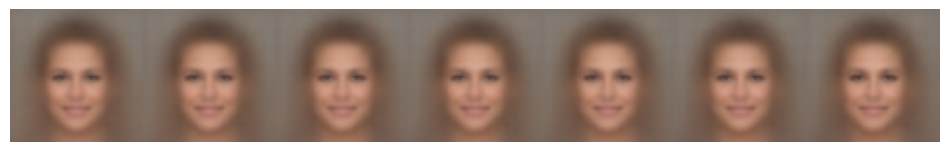

Latent traversal for β = 10
Latent traversal for dimension 3


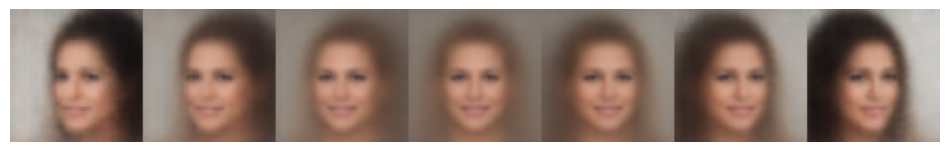

Latent traversal for β = 10
Latent traversal for dimension 7


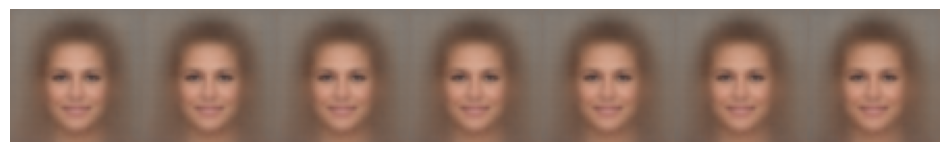

Latent traversal for β = 10
Latent traversal for dimension 12


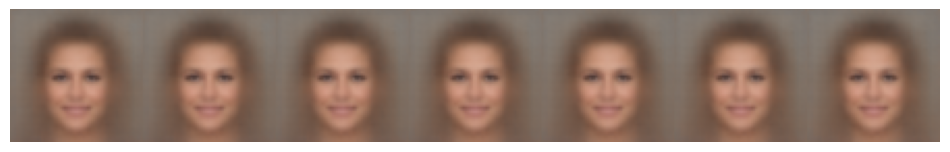

Latent traversal for β = 2 and dimension 5


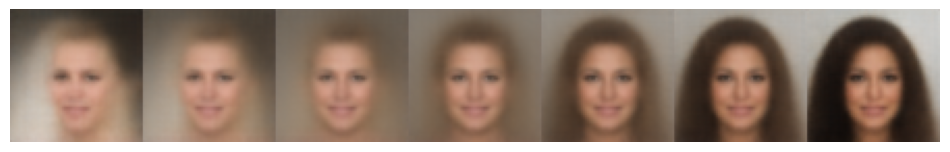

Latent traversal for β = 4 and dimension 5


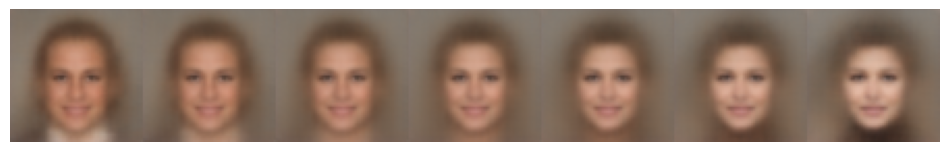

Latent traversal for β = 10 and dimension 5


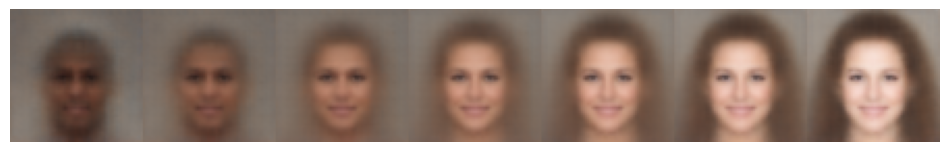

In [69]:
def latent_traversal(model, dim, steps=7):
    model.eval()
    with torch.no_grad():
        z = torch.zeros(1, LATENT_DIM).to(device)
        values = torch.linspace(-3, 3, steps)

        images = []
        for v in values:
            z[0, dim] = v
            img = model.decoder(model.fc_dec(z)).cpu()
            images.append(img)

        grid = torch.cat(images, dim=3)
        plt.figure(figsize=(12, 2))
        plt.imshow(grid[0].permute(1, 2, 0))
        plt.axis("off")
        plt.show()

# Latent traversal for multiple dimensions
# This helps identify which dimensions correspond to interpretable attributes

for dim in [0, 3, 7, 12]:
    print("Latent traversal for β = 10")
    print(f"Latent traversal for dimension {dim}")
    latent_traversal(vae_beta10, dim=dim)

# Each traversal varies only one latent dimension while keeping others fixed.
# This helps analyze disentanglement in the latent space.

print("Latent traversal for β = 2 and dimension 5")
latent_traversal(vae_beta2, dim=5)

print("Latent traversal for β = 4 and dimension 5")
latent_traversal(vae_beta4, dim=5)

print("Latent traversal for β = 10 and dimension 5")
latent_traversal(vae_beta10, dim=5)

## 9. Reconstruction Visualization


Reconstruction for β = 2


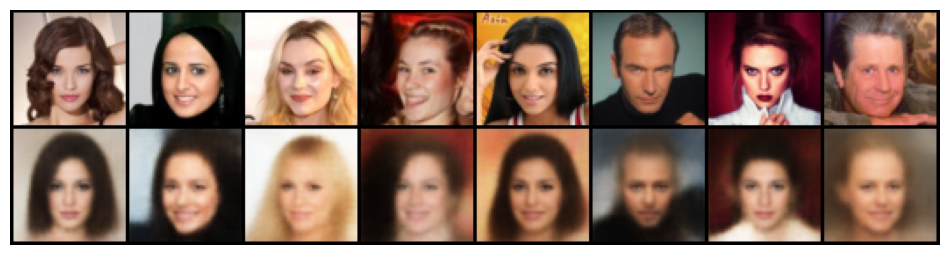

Reconstruction for β = 4


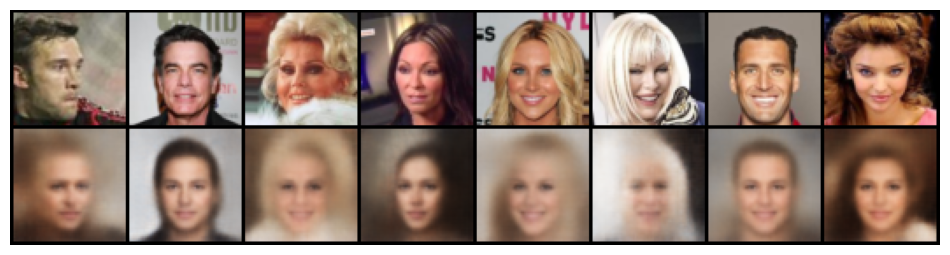

Reconstruction for β = 10


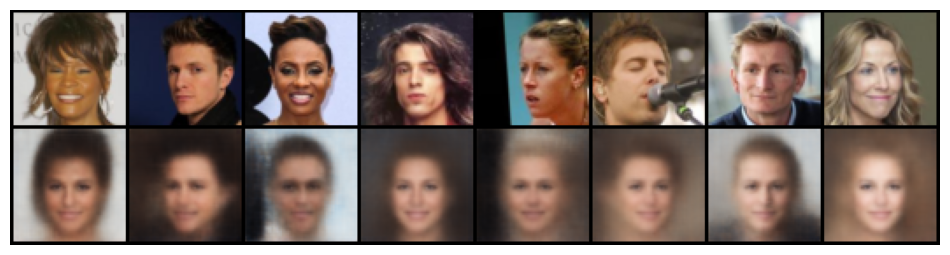

In [70]:
from torchvision.utils import make_grid

def show_reconstruction(model, loader):
    model.eval()
    with torch.no_grad():
        batch = next(iter(loader))
        x = batch[0][:8].to(device)
        x_hat, _, _, _ = model(x)

        # Combine originals and reconstructions
        imgs = torch.cat([x, x_hat], dim=0)

        # Create grid
        grid = make_grid(imgs, nrow=8)

        plt.figure(figsize=(12,4))
        plt.imshow(grid.permute(1,2,0).cpu())
        plt.axis("off")
        plt.show()


print("Reconstruction for β = 2")
show_reconstruction(vae_beta2, train_loader)

print("Reconstruction for β = 4")
show_reconstruction(vae_beta4, train_loader)

print("Reconstruction for β = 10")
show_reconstruction(vae_beta10, train_loader)


## 11. Summary and Results


**Observations from Latent Traversal and Reconstruction**

**β = 2 (Low β)**

- The model produces high-quality reconstructions with sharp facial details.
- During latent traversal, varying a single latent dimension leads to simultaneous changes in multiple facial attributes, such as expression, lighting, and pose.
- Individual latent variables are highly entangled, making it difficult to associate a specific dimension with a single semantic attribute.
- Although reconstruction fidelity is strong, controlled attribute manipulation is limited.

**β = 4 (Moderate β)**

- Reconstruction quality remains reasonably good, though slightly blurred compared to β = 2.
- Latent traversal shows partial disentanglement, where some dimensions begin to influence specific facial properties.
- Certain latent variables show weak correlation with attributes such as head orientation or expression, but changes are not consistently isolated.
- This setting represents a balance between reconstruction quality and emerging disentanglement, but attribute control is still limited.

**β = 10 (High β)**

- Reconstructions become noticeably blurrier, indicating a reduction in reconstruction fidelity.

- Latent traversal at this β value produces clear and interpretable variations, where individual latent dimensions correspond to distinct facial attributes.
- Specific dimensions were observed to control attributes such as: smiling intensity, head pose or orientation, gender-related facial structure.
- Other latent dimensions showed minimal or mixed effects, which is expected as not all dimensions capture dominant factors.
- Overall, β = 10 demonstrates strong disentanglement, making it the most suitable setting for controlled face attribute manipulation.

**Summary: Reconstruction vs Disentanglement Trade-off**

1.  Increasing β strengthens the KL-divergence regularization, which limits the information capacity of the latent space.
2.  Lower β values (β = 2) prioritize reconstruction accuracy but result in entangled latent representations.
3.  Moderate β values (β = 4) show intermediate behavior, with slight loss in reconstruction quality and partial disentanglement.
4.  Higher β values (β = 10) significantly improve disentanglement, allowing individual latent dimensions to control meaningful facial attributes, at the cost of reduced reconstruction fidelity.

**Conclusion:**
The experiments clearly demonstrate the fundamental trade-off in β-VAE models: **as β increases, reconstruction quality decreases while disentanglement and interpretability of the latent space improve**.

This behavior aligns with the theoretical objectives of β-VAE and validates its effectiveness for controllable face modification.


# Part C: VQ-VAE with PixelCNN Prior

1. VQ-VAE training and reconstruction
2. Discrete latent extraction
3. PixelCNN prior training
4. New face generation from sampled latents


## 1. Setup and Imports


In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import torchvision
from torchvision import transforms
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import os
import random
from PIL import Image

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

Using device: cpu


## 2. Data Loading


In [8]:
# Configuration
IMG_SIZE = 64  # Can use 128 for higher quality
BATCH_SIZE = 64
NUM_WORKERS = 4

# Data transforms
transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    # Normalize to [0, 1] is already done by ToTensor()
])

### Option 1: Load CelebA from Kaggle (Recommended)

```bash
# Install Kaggle API
pip install kaggle

# Download CelebA from Kaggle
kaggle datasets download -d jessicali9530/celeba-dataset
unzip celeba-dataset.zip -d ./data/celeba
```


### Option 2: Manual Download

Download from: https://www.kaggle.com/datasets/jessicali9530/celeba-dataset
Or from: https://mmlab.ie.cuhk.edu.hk/projects/CelebA.html


In [9]:
# Custom Dataset class for manually downloaded CelebA
class CelebADataset(Dataset):
    def __init__(self, root_dir, transform=None, split='train', max_samples=None):
        """
        Args:
            root_dir: Path to img_align_celeba folder
            transform: Transformations to apply
            split: 'train', 'val', or 'test'
            max_samples: Limit number of samples (useful for testing)
        """
        self.root_dir = root_dir
        self.transform = transform
        
        # Get all image files
        all_files = sorted([f for f in os.listdir(root_dir) if f.endswith('.jpg')])
        
        # Split dataset (CelebA has 202,599 images)
        # Train: 162,770 | Val: 19,867 | Test: 19,962
        if split == 'train':
            self.image_files = all_files[:162770]
        elif split == 'val':
            self.image_files = all_files[162770:182637]
        else:  # test
            self.image_files = all_files[182637:]
        
        if max_samples:
            self.image_files = self.image_files[:max_samples]
    
    def __len__(self):
        return len(self.image_files)
    
    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, self.image_files[idx])
        image = Image.open(img_path).convert('RGB')
        
        if self.transform:
            image = self.transform(image)
        
        return image, 0  # Return 0 as dummy label for compatibility

In [10]:
# Load CelebA dataset (real data from Kaggle)
CELEBA_PATH = './data/celeba/img_align_celeba/img_align_celeba'

print(f"Loading CelebA data from: {CELEBA_PATH}")
num_images = len([f for f in os.listdir(CELEBA_PATH) if f.endswith('.jpg')])
print(f"Available images: {num_images}")

# Create datasets
train_dataset = CelebADataset(
    root_dir=CELEBA_PATH,
    transform=transform,
    split='train',
    max_samples=None  # Use all data (set to e.g., 10000 for quick testing)
)

test_dataset = CelebADataset(
    root_dir=CELEBA_PATH,
    transform=transform,
    split='test',
    max_samples=None
)

# Create dataloaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print(f"\nTrain dataset size: {len(train_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")
print(f"Total CelebA images available: {len(train_dataset) + len(test_dataset)}")

Loading CelebA data from: ./data/celeba/img_align_celeba/img_align_celeba
Available images: 202599

Train dataset size: 162770
Test dataset size: 19962
Total CelebA images available: 182732


## 3. VQ-VAE Architecture


In [11]:
class VectorQuantizer(nn.Module):
    """
    Vector Quantization layer that maps continuous latents to discrete codes.
    """
    def __init__(self, num_embeddings, embedding_dim, commitment_cost=0.25):
        super(VectorQuantizer, self).__init__()
        
        self.num_embeddings = num_embeddings  # K (codebook size)
        self.embedding_dim = embedding_dim
        self.commitment_cost = commitment_cost
        
        # Codebook embeddings
        self.embedding = nn.Embedding(num_embeddings, embedding_dim)
        self.embedding.weight.data.uniform_(-1/num_embeddings, 1/num_embeddings)
        
    def forward(self, inputs):
        # inputs: [B, C, H, W]
        # Convert to [B, H, W, C]
        inputs = inputs.permute(0, 2, 3, 1).contiguous()
        input_shape = inputs.shape
        
        # Flatten to [BHW, C]
        flat_input = inputs.view(-1, self.embedding_dim)
        
        # Calculate distances to codebook entries
        distances = (torch.sum(flat_input**2, dim=1, keepdim=True) 
                    + torch.sum(self.embedding.weight**2, dim=1)
                    - 2 * torch.matmul(flat_input, self.embedding.weight.t()))
        
        # Get encoding indices (closest codebook entry)
        encoding_indices = torch.argmin(distances, dim=1).unsqueeze(1)
        
        # One-hot encodings
        encodings = torch.zeros(encoding_indices.shape[0], self.num_embeddings, device=inputs.device)
        encodings.scatter_(1, encoding_indices, 1)
        
        # Quantize
        quantized = torch.matmul(encodings, self.embedding.weight).view(input_shape)
        
        # Loss
        e_latent_loss = F.mse_loss(quantized.detach(), inputs)
        q_latent_loss = F.mse_loss(quantized, inputs.detach())
        loss = q_latent_loss + self.commitment_cost * e_latent_loss
        
        # Straight-through estimator
        quantized = inputs + (quantized - inputs).detach()
        
        # Convert back to [B, C, H, W]
        quantized = quantized.permute(0, 3, 1, 2).contiguous()
        
        return quantized, loss, encoding_indices.view(input_shape[0], input_shape[1], input_shape[2])


class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(ResidualBlock, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 1)
        self.relu = nn.ReLU(inplace=True)
        
    def forward(self, x):
        residual = x
        out = self.relu(self.conv1(x))
        out = self.conv2(out)
        out += residual
        return self.relu(out)


class Encoder(nn.Module):
    def __init__(self, in_channels=3, hidden_dims=[128, 256], latent_dim=64):
        super(Encoder, self).__init__()
        
        modules = []
        for h_dim in hidden_dims:
            modules.append(
                nn.Sequential(
                    nn.Conv2d(in_channels, h_dim, 4, stride=2, padding=1),
                    nn.ReLU(inplace=True)
                )
            )
            in_channels = h_dim
        
        modules.append(
            nn.Sequential(
                nn.Conv2d(hidden_dims[-1], latent_dim, 3, padding=1),
                ResidualBlock(latent_dim, latent_dim),
                ResidualBlock(latent_dim, latent_dim)
            )
        )
        
        self.encoder = nn.Sequential(*modules)
        
    def forward(self, x):
        return self.encoder(x)


class Decoder(nn.Module):
    def __init__(self, latent_dim=64, hidden_dims=[256, 128], out_channels=3):
        super(Decoder, self).__init__()
        
        modules = [
            nn.Sequential(
                ResidualBlock(latent_dim, latent_dim),
                ResidualBlock(latent_dim, latent_dim),
                nn.ConvTranspose2d(latent_dim, hidden_dims[0], 3, padding=1)
            )
        ]
        
        for i in range(len(hidden_dims) - 1):
            modules.append(
                nn.Sequential(
                    nn.ConvTranspose2d(hidden_dims[i], hidden_dims[i+1], 4, stride=2, padding=1),
                    nn.ReLU(inplace=True)
                )
            )
        
        modules.append(
            nn.Sequential(
                nn.ConvTranspose2d(hidden_dims[-1], out_channels, 4, stride=2, padding=1),
                nn.Sigmoid()  # Output in [0, 1]
            )
        )
        
        self.decoder = nn.Sequential(*modules)
        
    def forward(self, x):
        return self.decoder(x)


class VQVAE(nn.Module):
    def __init__(self, num_embeddings=512, embedding_dim=64, hidden_dims=[128, 256]):
        super(VQVAE, self).__init__()
        
        self.encoder = Encoder(in_channels=3, hidden_dims=hidden_dims, latent_dim=embedding_dim)
        self.vq_layer = VectorQuantizer(num_embeddings, embedding_dim)
        self.decoder = Decoder(latent_dim=embedding_dim, hidden_dims=list(reversed(hidden_dims)), out_channels=3)
        
    def forward(self, x):
        z = self.encoder(x)
        quantized, vq_loss, encoding_indices = self.vq_layer(z)
        x_recon = self.decoder(quantized)
        return x_recon, vq_loss, encoding_indices
    
    def encode(self, x):
        """Get discrete latent codes"""
        z = self.encoder(x)
        _, _, encoding_indices = self.vq_layer(z)
        return encoding_indices
    
    def decode_indices(self, indices):
        """Decode from discrete indices"""
        # Get quantized vectors from indices
        quantized = self.vq_layer.embedding(indices)
        # Reshape to [B, H, W, C] then to [B, C, H, W]
        quantized = quantized.permute(0, 3, 1, 2).contiguous()
        return self.decoder(quantized)

## 4. Training VQ-VAE


In [12]:
# VQ-VAE Configuration
NUM_EMBEDDINGS = 512  # Codebook size K
EMBEDDING_DIM = 64
HIDDEN_DIMS = [128, 256]
LEARNING_RATE = 1e-3
NUM_EPOCHS = 50

# Initialize model
vqvae = VQVAE(
    num_embeddings=NUM_EMBEDDINGS,
    embedding_dim=EMBEDDING_DIM,
    hidden_dims=HIDDEN_DIMS
).to(device)

# Optimizer
optimizer = optim.Adam(vqvae.parameters(), lr=LEARNING_RATE)

print(f"VQ-VAE Model Architecture:")
print(f"Codebook size: {NUM_EMBEDDINGS}")
print(f"Embedding dimension: {EMBEDDING_DIM}")
print(f"Total parameters: {sum(p.numel() for p in vqvae.parameters())}")

VQ-VAE Model Architecture:
Codebook size: 512
Embedding dimension: 64
Total parameters: 1553731


In [13]:
def train_vqvae(model, train_loader, optimizer, num_epochs, device):
    """
    Train VQ-VAE model
    """
    model.train()
    train_losses = []
    recon_losses = []
    vq_losses = []
    
    for epoch in range(num_epochs):
        epoch_loss = 0
        epoch_recon_loss = 0
        epoch_vq_loss = 0
        
        pbar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{num_epochs}')
        for batch_idx, (data, _) in enumerate(pbar):
            data = data.to(device)
            
            optimizer.zero_grad()
            
            # Forward pass
            recon, vq_loss, _ = model(data)
            
            # Reconstruction loss
            recon_loss = F.mse_loss(recon, data)
            
            # Total loss
            loss = recon_loss + vq_loss
            
            # Backward pass
            loss.backward()
            optimizer.step()
            
            epoch_loss += loss.item()
            epoch_recon_loss += recon_loss.item()
            epoch_vq_loss += vq_loss.item()
            
            pbar.set_postfix({
                'loss': loss.item(),
                'recon': recon_loss.item(),
                'vq': vq_loss.item()
            })
        
        # Average losses
        avg_loss = epoch_loss / len(train_loader)
        avg_recon = epoch_recon_loss / len(train_loader)
        avg_vq = epoch_vq_loss / len(train_loader)
        
        train_losses.append(avg_loss)
        recon_losses.append(avg_recon)
        vq_losses.append(avg_vq)
        
        print(f'Epoch {epoch+1}: Loss={avg_loss:.4f}, Recon={avg_recon:.4f}, VQ={avg_vq:.4f}')
        
        # Save checkpoint every 10 epochs
        if (epoch + 1) % 10 == 0:
            torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'loss': avg_loss,
            }, f'vqvae_checkpoint_epoch_{epoch+1}.pth')
    
    return train_losses, recon_losses, vq_losses

In [ ]:
# Train the VQ-VAE
train_losses, recon_losses, vq_losses = train_vqvae(
    vqvae, train_loader, optimizer, NUM_EPOCHS, device
)

# Save final model
torch.save(vqvae.state_dict(), 'vqvae_final.pth')

Epoch 1/50:   0%|          | 0/2544 [00:00<?, ?it/s]C:\Users\Manindra\AppData\Roaming\Python\Python312\site-packages\torch\utils\data\dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


## 5. Visualize Training Curves


In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.plot(train_losses)
plt.xlabel('Epoch')
plt.ylabel('Total Loss')
plt.title('VQ-VAE Training Loss')
plt.grid(True)

plt.subplot(1, 3, 2)
plt.plot(recon_losses)
plt.xlabel('Epoch')
plt.ylabel('Reconstruction Loss')
plt.title('Reconstruction Loss')
plt.grid(True)

plt.subplot(1, 3, 3)
plt.plot(vq_losses)
plt.xlabel('Epoch')
plt.ylabel('VQ Loss')
plt.title('Vector Quantization Loss')
plt.grid(True)

plt.tight_layout()
plt.savefig('vqvae_training_curves.png', dpi=300, bbox_inches='tight')
plt.show()

## 6. Task 1 & 2: Reconstruction Quality and Discrete Latent Extraction


In [ ]:
def visualize_reconstructions(model, test_loader, device, num_images=8):
    """
    Visualize original vs reconstructed images
    """
    model.eval()
    
    with torch.no_grad():
        # Get a batch
        data, _ = next(iter(test_loader))
        data = data[:num_images].to(device)
        
        # Reconstruct
        recon, _, encoding_indices = model(data)
        
        # Move to CPU for visualization
        data = data.cpu()
        recon = recon.cpu()
        
        # Plot
        fig, axes = plt.subplots(2, num_images, figsize=(20, 5))
        for i in range(num_images):
            # Original
            axes[0, i].imshow(data[i].permute(1, 2, 0))
            axes[0, i].axis('off')
            if i == 0:
                axes[0, i].set_title('Original', fontsize=12)
            
            # Reconstruction
            axes[1, i].imshow(recon[i].permute(1, 2, 0))
            axes[1, i].axis('off')
            if i == 0:
                axes[1, i].set_title('Reconstructed', fontsize=12)
        
        plt.tight_layout()
        plt.savefig('vqvae_reconstructions.png', dpi=300, bbox_inches='tight')
        plt.show()
        
        # Calculate reconstruction error
        mse = F.mse_loss(recon, data)
        print(f"\nReconstruction MSE: {mse.item():.6f}")
        print(f"Latent map shape: {encoding_indices.shape}")
        print(f"Unique codes used: {len(torch.unique(encoding_indices))} / {NUM_EMBEDDINGS}")
        
        return encoding_indices

# Visualize reconstructions
latent_indices = visualize_reconstructions(vqvae, test_loader, device)

In [ ]:
def extract_all_latents(model, dataloader, device, max_samples=10000):
    """
    Extract discrete latent codes from dataset for PixelCNN training
    """
    model.eval()
    all_latents = []
    
    with torch.no_grad():
        for batch_idx, (data, _) in enumerate(tqdm(dataloader, desc='Extracting latents')):
            if batch_idx * dataloader.batch_size >= max_samples:
                break
                
            data = data.to(device)
            encoding_indices = model.encode(data)
            all_latents.append(encoding_indices.cpu())
    
    all_latents = torch.cat(all_latents, dim=0)
    print(f"Extracted latents shape: {all_latents.shape}")
    
    return all_latents

# Extract latents for PixelCNN training
train_latents = extract_all_latents(vqvae, train_loader, device, max_samples=50000)

# Save latents
torch.save(train_latents, 'train_latents.pt')

## 7. PixelCNN Prior Architecture


In [ ]:
class MaskedConv2d(nn.Conv2d):
    """
    Masked convolution for autoregressive modeling
    """
    def __init__(self, mask_type, *args, **kwargs):
        super(MaskedConv2d, self).__init__(*args, **kwargs)
        assert mask_type in ['A', 'B']
        self.register_buffer('mask', self.weight.data.clone())
        
        _, _, kH, kW = self.weight.size()
        self.mask.fill_(1)
        self.mask[:, :, kH // 2, kW // 2 + (mask_type == 'B'):] = 0
        self.mask[:, :, kH // 2 + 1:] = 0

    def forward(self, x):
        self.weight.data *= self.mask
        return super(MaskedConv2d, self).forward(x)


class ResidualBlock(nn.Module):
    def __init__(self, h):
        super(ResidualBlock, self).__init__()
        self.conv1 = MaskedConv2d('B', h, h // 2, 1)
        self.conv2 = MaskedConv2d('B', h // 2, h // 2, 7, padding=3)
        self.conv3 = MaskedConv2d('B', h // 2, h, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        residual = x
        out = self.relu(self.conv1(x))
        out = self.relu(self.conv2(out))
        out = self.conv3(out)
        return self.relu(out + residual)


class PixelCNN(nn.Module):
    """
    PixelCNN prior for VQ-VAE latent codes
    """
    def __init__(self, num_embeddings, num_layers=15, hidden_dim=128):
        super(PixelCNN, self).__init__()
        
        self.num_embeddings = num_embeddings
        
        # Initial masked convolution
        self.conv1 = MaskedConv2d('A', num_embeddings, hidden_dim, 7, padding=3)
        
        # Residual blocks
        self.residual_blocks = nn.ModuleList(
            [ResidualBlock(hidden_dim) for _ in range(num_layers)]
        )
        
        # Output layers
        self.conv_out1 = MaskedConv2d('B', hidden_dim, hidden_dim, 1)
        self.conv_out2 = MaskedConv2d('B', hidden_dim, num_embeddings, 1)
        
        self.relu = nn.ReLU()

    def forward(self, x):
        # x: [B, H, W] with values in [0, num_embeddings-1]
        # Convert to one-hot: [B, num_embeddings, H, W]
        batch_size, height, width = x.shape
        x_one_hot = F.one_hot(x.long(), num_classes=self.num_embeddings)
        x_one_hot = x_one_hot.permute(0, 3, 1, 2).float()
        
        # Forward pass
        out = self.relu(self.conv1(x_one_hot))
        
        for block in self.residual_blocks:
            out = block(out)
        
        out = self.relu(self.conv_out1(out))
        out = self.conv_out2(out)
        
        return out  # [B, num_embeddings, H, W]
    
    def sample(self, batch_size, height, width, device, temperature=1.0):
        """
        Sample new latent codes autoregressively
        """
        self.eval()
        samples = torch.zeros(batch_size, height, width, dtype=torch.long).to(device)
        
        with torch.no_grad():
            for i in tqdm(range(height), desc='Sampling rows'):
                for j in range(width):
                    # Get logits for current position
                    logits = self(samples)
                    
                    # Apply temperature
                    logits = logits[:, :, i, j] / temperature
                    
                    # Sample from categorical distribution
                    probs = F.softmax(logits, dim=1)
                    sampled_indices = torch.multinomial(probs, 1).squeeze(1)
                    
                    samples[:, i, j] = sampled_indices
        
        return samples

## 8. Task 3: Train PixelCNN on Latents


In [ ]:
# Create dataset for latent codes
class LatentDataset(Dataset):
    def __init__(self, latents):
        self.latents = latents
    
    def __len__(self):
        return len(self.latents)
    
    def __getitem__(self, idx):
        return self.latents[idx]

# Create dataloader
latent_dataset = LatentDataset(train_latents)
latent_loader = DataLoader(
    latent_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=4
)

# Initialize PixelCNN
pixelcnn = PixelCNN(
    num_embeddings=NUM_EMBEDDINGS,
    num_layers=15,
    hidden_dim=128
).to(device)

# Optimizer
pixelcnn_optimizer = optim.Adam(pixelcnn.parameters(), lr=3e-4)

print(f"PixelCNN Model:")
print(f"Total parameters: {sum(p.numel() for p in pixelcnn.parameters())}")

In [ ]:
def train_pixelcnn(model, dataloader, optimizer, num_epochs, device):
    """
    Train PixelCNN prior
    """
    model.train()
    losses = []
    
    for epoch in range(num_epochs):
        epoch_loss = 0
        
        pbar = tqdm(dataloader, desc=f'Epoch {epoch+1}/{num_epochs}')
        for batch_idx, latents in enumerate(pbar):
            latents = latents.to(device)
            
            optimizer.zero_grad()
            
            # Forward pass
            logits = model(latents)
            
            # Cross-entropy loss
            loss = F.cross_entropy(
                logits.permute(0, 2, 3, 1).reshape(-1, model.num_embeddings),
                latents.reshape(-1).long()
            )
            
            # Backward pass
            loss.backward()
            optimizer.step()
            
            epoch_loss += loss.item()
            pbar.set_postfix({'loss': loss.item()})
        
        avg_loss = epoch_loss / len(dataloader)
        losses.append(avg_loss)
        print(f'Epoch {epoch+1}: Loss={avg_loss:.4f}')
        
        # Save checkpoint
        if (epoch + 1) % 5 == 0:
            torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'loss': avg_loss,
            }, f'pixelcnn_checkpoint_epoch_{epoch+1}.pth')
    
    return losses

# Train PixelCNN
PIXELCNN_EPOCHS = 30
pixelcnn_losses = train_pixelcnn(
    pixelcnn, latent_loader, pixelcnn_optimizer, PIXELCNN_EPOCHS, device
)

# Save final model
torch.save(pixelcnn.state_dict(), 'pixelcnn_final.pth')

In [ ]:
# Plot PixelCNN training curve
plt.figure(figsize=(10, 6))
plt.plot(pixelcnn_losses)
plt.xlabel('Epoch')
plt.ylabel('Cross-Entropy Loss')
plt.title('PixelCNN Training Loss')
plt.grid(True)
plt.savefig('pixelcnn_training_curve.png', dpi=300, bbox_inches='tight')
plt.show()

## 9. Task 4 & 5: Sample New Faces from PixelCNN


In [ ]:
def generate_faces_from_prior(vqvae, pixelcnn, num_samples, device, temperature=1.0):
    """
    Generate new faces by:
    1. Sample latent codes from PixelCNN
    2. Decode with VQ-VAE decoder
    """
    vqvae.eval()
    pixelcnn.eval()
    
    # Get latent spatial dimensions
    # For 64x64 images with 2 downsampling layers: 16x16
    latent_h = IMG_SIZE // (2 ** len(HIDDEN_DIMS))
    latent_w = IMG_SIZE // (2 ** len(HIDDEN_DIMS))
    
    print(f"Sampling {num_samples} latent codes of shape [{latent_h}, {latent_w}]...")
    
    # Sample latent codes from PixelCNN
    sampled_latents = pixelcnn.sample(
        batch_size=num_samples,
        height=latent_h,
        width=latent_w,
        device=device,
        temperature=temperature
    )
    
    print("Decoding latents to images...")
    
    # Decode to images
    with torch.no_grad():
        generated_images = vqvae.decode_indices(sampled_latents)
    
    return generated_images.cpu(), sampled_latents.cpu()

# Generate faces
NUM_GENERATED = 16
TEMPERATURE = 1.0  # Lower = more conservative, higher = more diverse

generated_faces, sampled_latents = generate_faces_from_prior(
    vqvae, pixelcnn, NUM_GENERATED, device, temperature=TEMPERATURE
)

In [ ]:
# Visualize generated faces
def visualize_generated_faces(faces, num_cols=4):
    num_images = len(faces)
    num_rows = (num_images + num_cols - 1) // num_cols
    
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols*3, num_rows*3))
    axes = axes.flatten() if num_images > 1 else [axes]
    
    for i in range(num_images):
        img = faces[i].permute(1, 2, 0).numpy()
        img = np.clip(img, 0, 1)
        axes[i].imshow(img)
        axes[i].axis('off')
        axes[i].set_title(f'Sample {i+1}')
    
    # Hide extra subplots
    for i in range(num_images, len(axes)):
        axes[i].axis('off')
    
    plt.tight_layout()
    plt.savefig('vqvae_generated_faces.png', dpi=300, bbox_inches='tight')
    plt.show()

visualize_generated_faces(generated_faces)

## 10. Additional Analysis


In [ ]:
# Generate faces with different temperatures
temperatures = [0.7, 1.0, 1.2]

fig, axes = plt.subplots(len(temperatures), 4, figsize=(12, 3*len(temperatures)))

for idx, temp in enumerate(temperatures):
    faces, _ = generate_faces_from_prior(vqvae, pixelcnn, 4, device, temperature=temp)
    
    for i in range(4):
        img = faces[i].permute(1, 2, 0).numpy()
        img = np.clip(img, 0, 1)
        axes[idx, i].imshow(img)
        axes[idx, i].axis('off')
        if i == 0:
            axes[idx, i].set_ylabel(f'T={temp}', fontsize=14)

plt.suptitle('Generated Faces with Different Temperatures', fontsize=16)
plt.tight_layout()
plt.savefig('vqvae_temperature_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# Codebook usage analysis
def analyze_codebook_usage(vqvae, dataloader, device, num_batches=50):
    """
    Analyze which codebook entries are being used
    """
    vqvae.eval()
    codebook_usage = torch.zeros(NUM_EMBEDDINGS)
    
    with torch.no_grad():
        for batch_idx, (data, _) in enumerate(dataloader):
            if batch_idx >= num_batches:
                break
            
            data = data.to(device)
            indices = vqvae.encode(data)
            
            # Count usage
            unique, counts = torch.unique(indices.cpu(), return_counts=True)
            for idx, count in zip(unique, counts):
                codebook_usage[idx] += count
    
    # Plot
    plt.figure(figsize=(12, 5))
    
    plt.subplot(1, 2, 1)
    plt.bar(range(NUM_EMBEDDINGS), codebook_usage.numpy())
    plt.xlabel('Codebook Index')
    plt.ylabel('Usage Count')
    plt.title('Codebook Usage Distribution')
    
    plt.subplot(1, 2, 2)
    plt.hist(codebook_usage.numpy(), bins=50)
    plt.xlabel('Usage Count')
    plt.ylabel('Number of Codes')
    plt.title('Codebook Usage Histogram')
    
    plt.tight_layout()
    plt.savefig('codebook_usage_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    used_codes = (codebook_usage > 0).sum().item()
    print(f"\nCodebook Statistics:")
    print(f"Total codes: {NUM_EMBEDDINGS}")
    print(f"Used codes: {used_codes} ({100*used_codes/NUM_EMBEDDINGS:.2f}%)")
    print(f"Unused codes: {NUM_EMBEDDINGS - used_codes}")
    print(f"Average usage per code: {codebook_usage.mean():.2f}")
    print(f"Max usage: {codebook_usage.max():.0f}")

analyze_codebook_usage(vqvae, test_loader, device)

## 11. Summary and Results


In [ ]:
print("="*60)
print("VQ-VAE + PixelCNN Results Summary")
print("="*60)
print(f"\n1. VQ-VAE Architecture:")
print(f"   - Codebook size: {NUM_EMBEDDINGS}")
print(f"   - Embedding dimension: {EMBEDDING_DIM}")
print(f"   - Image size: {IMG_SIZE}x{IMG_SIZE}")
print(f"   - Latent map size: {IMG_SIZE//(2**len(HIDDEN_DIMS))}x{IMG_SIZE//(2**len(HIDDEN_DIMS))}")

print(f"\n2. Training:")
print(f"   - VQ-VAE epochs: {NUM_EPOCHS}")
print(f"   - PixelCNN epochs: {PIXELCNN_EPOCHS}")
print(f"   - Final VQ-VAE loss: {train_losses[-1]:.4f}")
print(f"   - Final PixelCNN loss: {pixelcnn_losses[-1]:.4f}")

print(f"\n3. Reconstruction Quality:")
vqvae.eval()
with torch.no_grad():
    test_data, _ = next(iter(test_loader))
    test_data = test_data.to(device)
    recon, _, _ = vqvae(test_data)
    test_mse = F.mse_loss(recon, test_data)
    print(f"   - Test MSE: {test_mse.item():.6f}")

print(f"\n4. Generation:")
print(f"   - Generated {NUM_GENERATED} new face samples")
print(f"   - Sampling temperature: {TEMPERATURE}")

print(f"\n5. Key Findings:")
print(f"   - VQ-VAE learns discrete latent representations")
print(f"   - PixelCNN models the prior distribution over latents")
print(f"   - Can generate new faces by sampling from prior")
print(f"   - Temperature controls diversity vs quality trade-off")

print("\n" + "="*60)
print("Files saved:")
print("  - vqvae_final.pth (VQ-VAE weights)")
print("  - pixelcnn_final.pth (PixelCNN weights)")
print("  - train_latents.pt (Extracted latents)")
print("  - vqvae_training_curves.png")
print("  - vqvae_reconstructions.png")
print("  - pixelcnn_training_curve.png")
print("  - vqvae_generated_faces.png")
print("  - vqvae_temperature_comparison.png")
print("  - codebook_usage_analysis.png")
print("="*60)

# Part D - GAN for face Generation


In [2]:
import os

# setting kagle details
os.environ['KAGGLE_USERNAME'] = "kaggle.com/nikisag"
os.environ['KAGGLE_KEY'] = "KGAT_d1ebed41516390b8c6b32f0ccbd7494e"

# This creates the necessary config file automatically so the API works
!mkdir -p ~/.kaggle
!echo '{"username":"'$KAGGLE_USERNAME'","key":"'$KAGGLE_KEY'"}' > ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

print("Kaggle API successfully configured!")

Kaggle API successfully configured!


In [3]:
# 1. Download the zip file
!kaggle datasets download -d jessicali9530/celeba-dataset

# 2. Unzip it (This takes a minute or two as there are 200k+ images)
import zipfile

print("Unzipping... please wait.")
with zipfile.ZipFile("celeba-dataset.zip", "r") as zip_ref:
    zip_ref.extractall("celeba_data")

print("Done! Your images are in: celeba_data/img_align_celeba/img_align_celeba/")

Dataset URL: https://www.kaggle.com/datasets/jessicali9530/celeba-dataset
License(s): other
 98% 1.30G/1.33G [00:15<00:00, 49.6MB/s]
100% 1.33G/1.33G [00:15<00:00, 91.0MB/s]
Unzipping... please wait.
Done! Your images are in: celeba_data/img_align_celeba/img_align_celeba/


In [4]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import numpy as np

# 1. Preprocessing as per PDF (64x64, Normalize [0,1])
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(), # Automatically scales pixels to [0, 1.0]
])

# 2. Load the full dataset (assuming unzipped in 'celeba_data')
full_dataset = datasets.ImageFolder(root='celeba_data/img_align_celeba', transform=transform)

# 3. FASTER PROCESSING: Use only 10,000 images
subset_indices = np.arange(100000)
fast_dataset = Subset(full_dataset, subset_indices)

# 4. Optimized DataLoader
batch_size = 128 # Larger batch size for faster GPU processing
dataloader = DataLoader(fast_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dataset ready: Using {len(fast_dataset)} images on {device}")

Dataset ready: Using 100000 images on cuda


In [5]:
import torch.nn as nn

latent_dim = 100

class Generator(nn.Module):
    def __init__(self):
        super(Generator, self).__init__()
        self.main = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, 512, 4, 1, 0, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(True),
            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            nn.ConvTranspose2d(64, 3, 4, 2, 1, bias=False),
            nn.Sigmoid() # Keep this: ensures output is [0, 1] per assignment
        )
    def forward(self, x): return self.main(x)

class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()
        self.main = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(256, 512, 4, 2, 1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(512, 1, 4, 1, 0, bias=False)
            # Sigmoid removed from here to allow BCEWithLogitsLoss (Fast Autocast)
        )
    def forward(self, x): return self.main(x)

netG = Generator().to(device)
netD = Discriminator().to(device)
print("Models updated for speed and stability.")

Models updated for speed and stability.


In [7]:
import torch.optim as optim
from torch import amp # Updated syntax

# BCEWithLogitsLoss is faster and safer for 'autocast'
criterion = nn.BCEWithLogitsLoss()
optimizerD = optim.Adam(netD.parameters(), lr=0.0002, betas=(0.5, 0.999))
optimizerG = optim.Adam(netG.parameters(), lr=0.0002, betas=(0.5, 0.999))
scaler = amp.GradScaler()

epochs = 40
print("Starting Optimized Training (Step 3)...")

for epoch in range(epochs):
    for i, (data, _) in enumerate(dataloader):
        real = data.to(device)
        b_size = real.size(0)

        # --- Update Discriminator ---
        optimizerD.zero_grad()
        with amp.autocast(device_type='cuda'):
            # Real
            out_real = netD(real).view(-1)
            loss_real = criterion(out_real, torch.full((b_size,), 1.0, device=device))
            # Fake
            noise = torch.randn(b_size, latent_dim, 1, 1, device=device)
            fake = netG(noise)
            out_fake = netD(fake.detach()).view(-1)
            loss_fake = criterion(out_fake, torch.full((b_size,), 0.0, device=device))
            loss_D = loss_real + loss_fake

        scaler.scale(loss_D).backward()
        scaler.step(optimizerD)

        # --- Update Generator ---
        optimizerG.zero_grad()
        with amp.autocast(device_type='cuda'):
            out_g = netD(fake).view(-1)
            loss_G = criterion(out_g, torch.full((b_size,), 1.0, device=device))

        scaler.scale(loss_G).backward()
        scaler.step(optimizerG)
        scaler.update()

    print(f"Epoch [{epoch+1}/{epochs}] complete. Loss D: {loss_D:.4f}, Loss G: {loss_G:.4f}")

Starting Optimized Training (Step 3)...
Epoch [1/40] complete. Loss D: 0.1214, Loss G: 6.1911
Epoch [2/40] complete. Loss D: 0.3245, Loss G: 3.1210
Epoch [3/40] complete. Loss D: 0.2505, Loss G: 2.9944
Epoch [4/40] complete. Loss D: 0.1170, Loss G: 4.3596
Epoch [5/40] complete. Loss D: 0.1172, Loss G: 5.1917
Epoch [6/40] complete. Loss D: 0.1169, Loss G: 5.2805
Epoch [7/40] complete. Loss D: 0.1950, Loss G: 4.5794
Epoch [8/40] complete. Loss D: 0.0278, Loss G: 5.0106
Epoch [9/40] complete. Loss D: 0.1137, Loss G: 6.6134
Epoch [10/40] complete. Loss D: 0.1158, Loss G: 3.4672
Epoch [11/40] complete. Loss D: 0.0995, Loss G: 6.1793
Epoch [12/40] complete. Loss D: 0.0572, Loss G: 6.2438
Epoch [13/40] complete. Loss D: 0.0713, Loss G: 5.3024
Epoch [14/40] complete. Loss D: 0.0454, Loss G: 5.0480
Epoch [15/40] complete. Loss D: 0.1378, Loss G: 5.2225
Epoch [16/40] complete. Loss D: 0.0361, Loss G: 5.5596
Epoch [17/40] complete. Loss D: 0.1454, Loss G: 10.7200
Epoch [18/40] complete. Loss D: 0

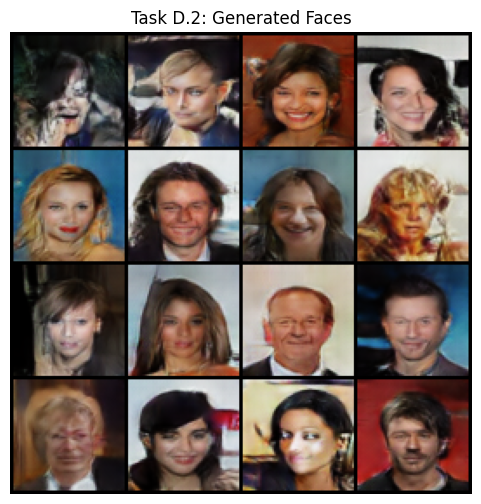

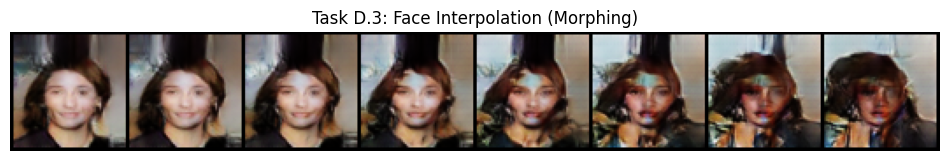

In [8]:
import matplotlib.pyplot as plt
from torchvision.utils import make_grid

# TASK D.2: Random Samples
with torch.no_grad():
    test_noise = torch.randn(16, 100, 1, 1, device=device)
    samples = netG(test_noise).cpu()

plt.figure(figsize=(6,6))
plt.imshow(make_grid(samples, nrow=4).permute(1, 2, 0))
plt.title("Task D.2: Generated Faces")
plt.axis('off')
plt.show()

# TASK D.3: Latent Interpolation
z1 = torch.randn(1, 100, 1, 1, device=device)
z2 = torch.randn(1, 100, 1, 1, device=device)
interp_steps = []
for alpha in torch.linspace(0, 1, 8):
    z_interp = (1 - alpha) * z1 + alpha * z2
    with torch.no_grad():
        interp_steps.append(netG(z_interp))

plt.figure(figsize=(12,4))
plt.imshow(make_grid(torch.cat(interp_steps), nrow=8).cpu().permute(1, 2, 0))
plt.title("Task D.3: Face Interpolation (Morphing)")
plt.axis('off')
plt.show()

###########################






##########################

# Part E Comparative Analysis


This section compares VAE, β‑VAE, VQ‑VAE + PixelCNN, and GAN using the SAME visual results generated in Parts A–D. Insert the corresponding figures from the notebook/PDF at the marked locations below.

Variational Autoencoder (VAE)
• Reconstructions preserve face structure but appear slightly blurry. • Interpolation shows smooth morphing between identities. • Attribute vector arithmetic (smile/bald) works but changes are not perfectly isolated. • Easy and stable training baseline.

β‑VAE LATENT TRAVERSAL images for β = 2, 4, 10 • β = 2 → sharp reconstructions but entangled latent variables. • β = 4 → moderate blur with partial disentanglement. • β = 10 → blurrier images but clear control of smile, pose, lighting. • Best model for controllable attribute editing.

VQ‑VAE + PixelCNN • Sharper and more detailed reconstructions than VAE/β‑VAE. • Discrete codebook captures fine facial details. • PixelCNN prior generates diverse realistic faces. • Harder training and less intuitive latent editing

GAN • Most realistic and sharp face images. • Excellent random sampling quality. • No encoder → reconstruction/editing difficult. • Training can be unstable.

Conclusion From the visual evidence, GAN provides the highest realism, β‑VAE offers the best latent control, VQ‑VAE gives sharp reconstructions, and VAE serves as a stable baseline. Therefore, model choice depends on whether the goal is editing, reconstruction quality, or realism.
